In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
os.environ['OMP_NUM_THREADS'] = '32'

In [3]:
sys.path.insert(0, '../pollux/')
import pollux
from tqdm.auto import trange, tqdm

# Create reader and shell builder objects

In [10]:
hacc_dir = '/global/cscratch1/sd/desc/HOS_Sims/L845/HACC150/'
shell_dir = '/global/cscratch1/sd/xuod/HACC/shells_z19_subsampleauto/'
nside = 2048
cosmo = pollux.cosmo.cosmo_hacc
seed = 12345

# Simulation reader
reader = pollux.reader.HACCReader(path=hacc_dir, aminstep=0.05)

# Shell builder
builder = pollux.shells.ShellBuilder(reader, cosmo, nside, save_dir=shell_dir, apply_random_isometry=True, seed=seed, subsample_box='auto')

Subsampling snapshots with aminstep=0.05 returns 19 snapshots


In [11]:
print(f'Box comoving size = {reader.get_boxsize(cosmo)} Mpc')
print(f'Building {reader.nshells} shells at redshift {np.round(reader.zsnapshots,2)}')

Box comoving size = 845.0704225352113 Mpc
Building 19 shells at redshift [0.   0.02 0.07 0.13 0.18 0.24 0.32 0.4  0.49 0.6  0.74 0.89 1.08 1.32
 1.61 1.95 2.41 3.04 4.  ]


In [12]:
shells = builder.load_shells()

../pollux/pollux/shells.py:473: RuntimeWarning: invalid value encountered in log10
  hp_map = np.log10(hp_map)
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:920: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("viridis").copy()
  newcm.set_over(newcm(1.0))
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:921: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("viridis").copy()
  newcm.set_under(bgcolor)
/global/homes/x/xuod/.conda

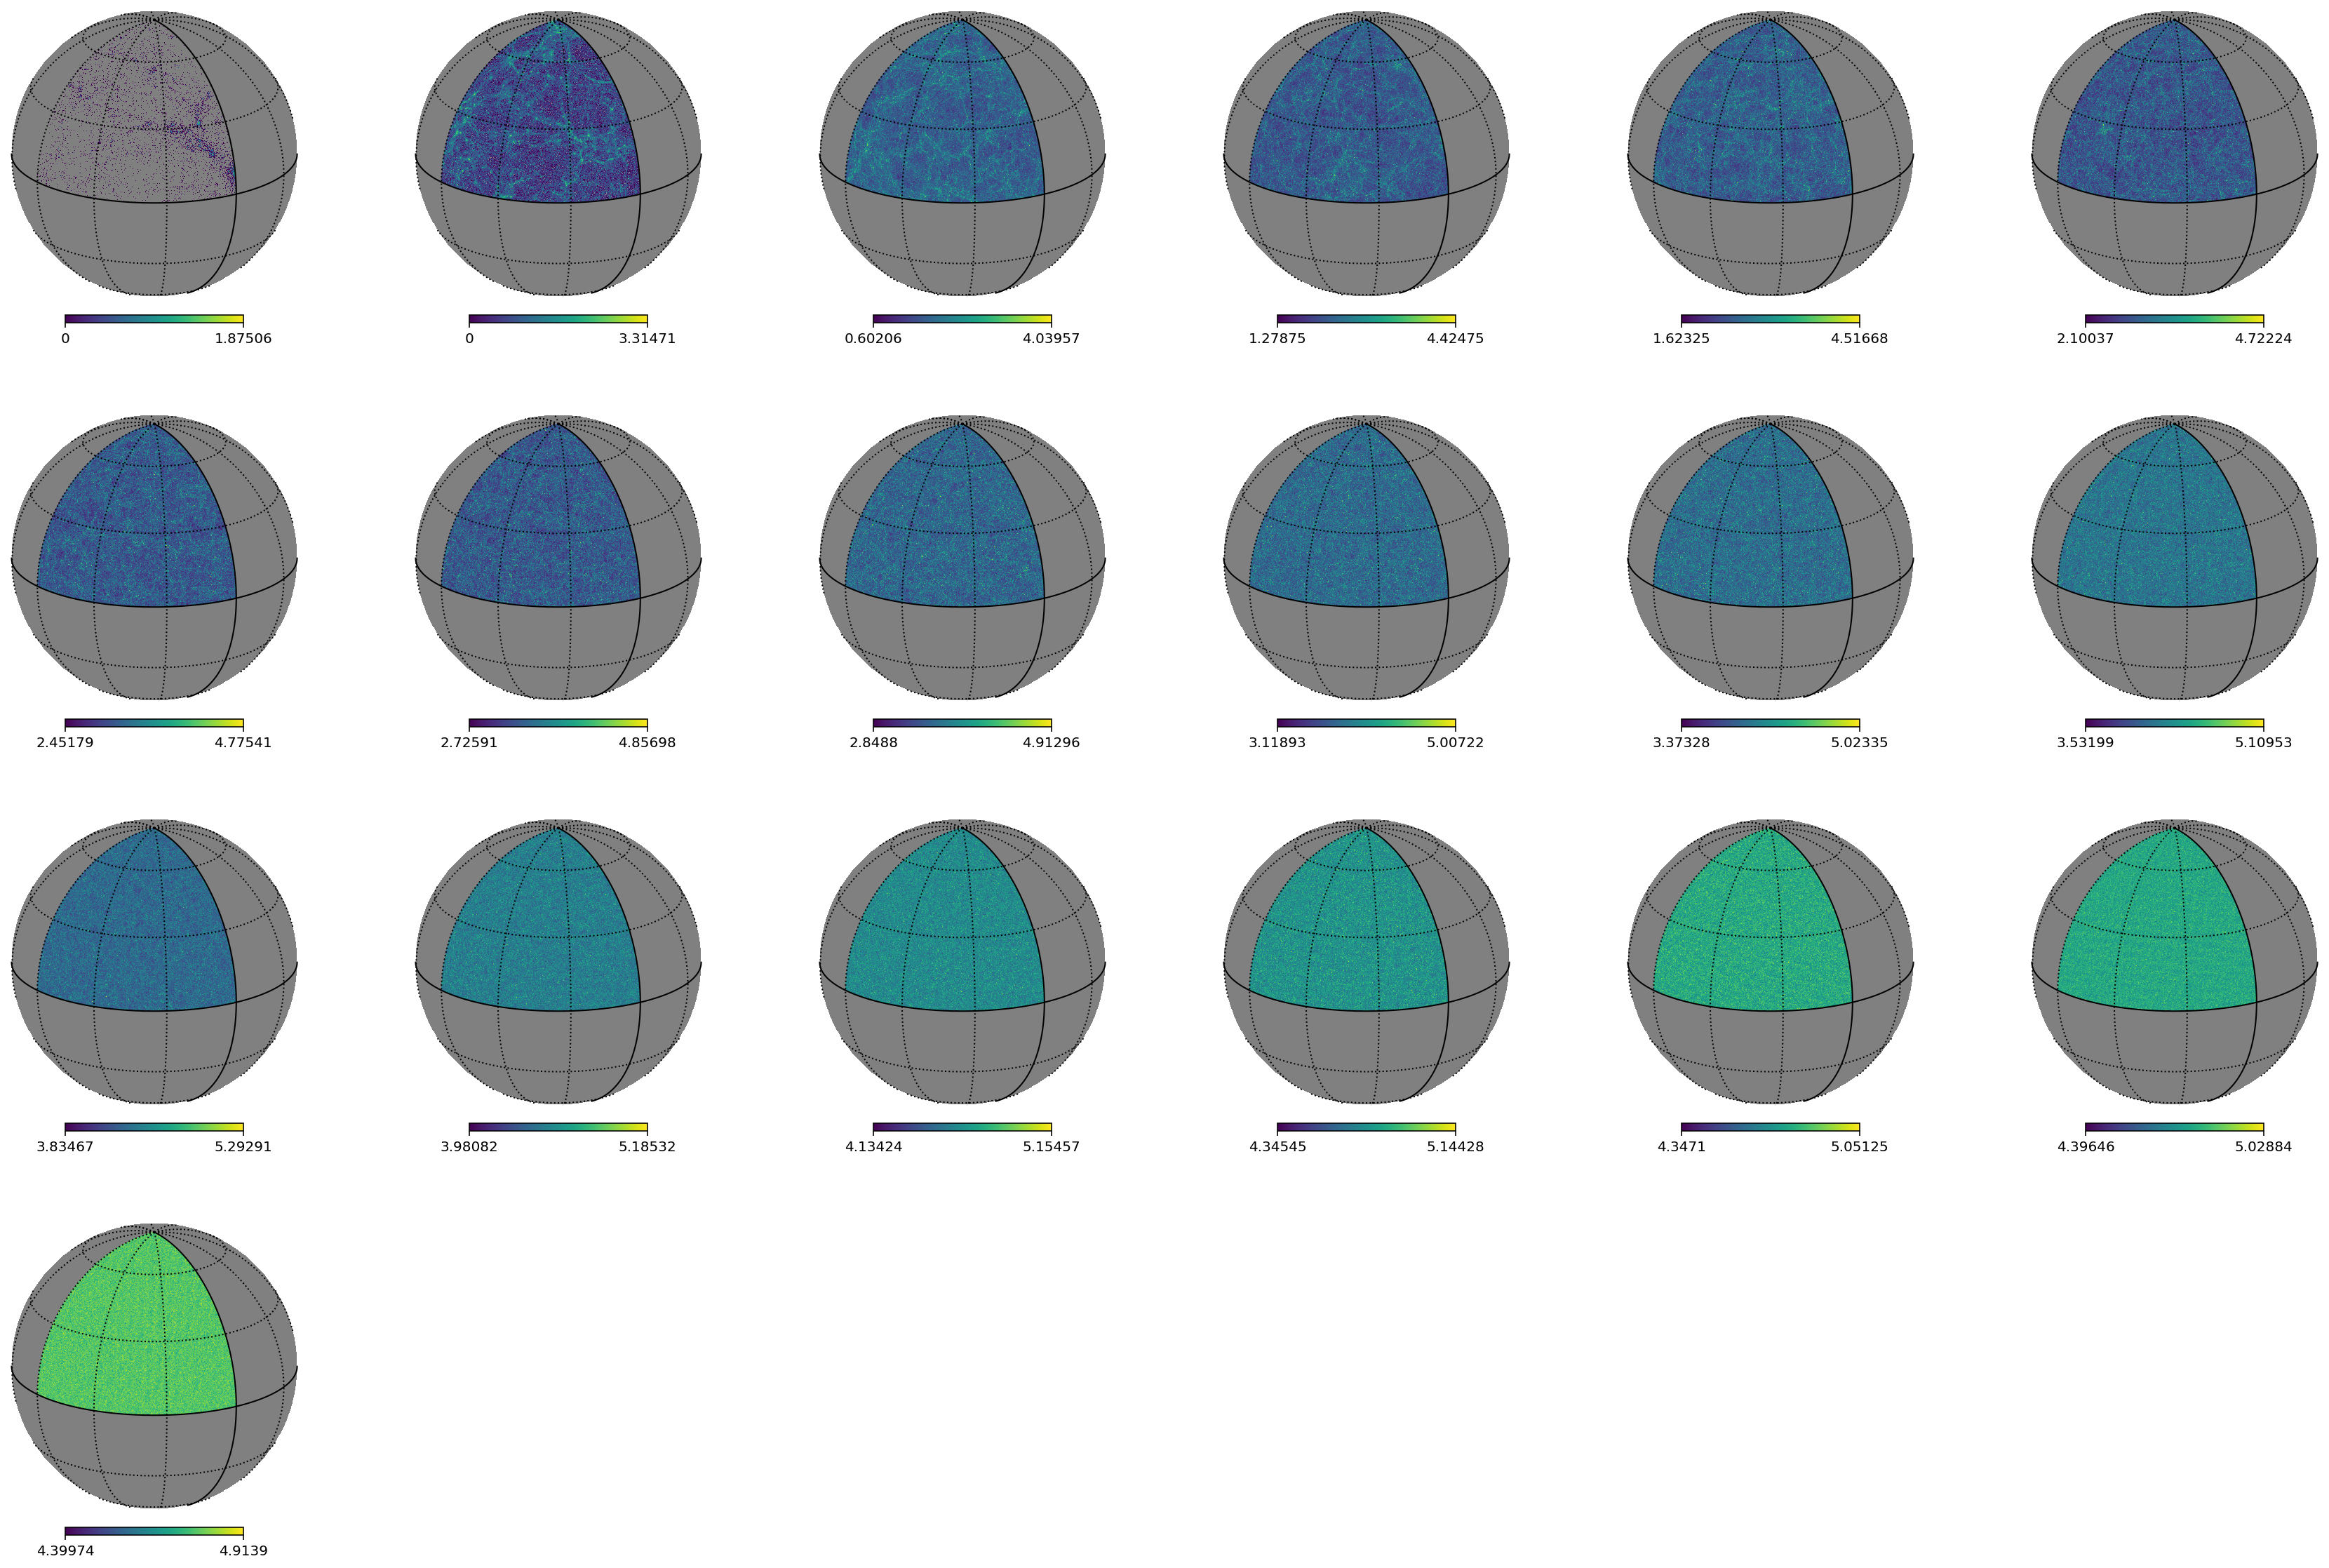

In [13]:
builder.plot_shells(shells, cbar=True, log=True, nx=6)

# Create lensing maps

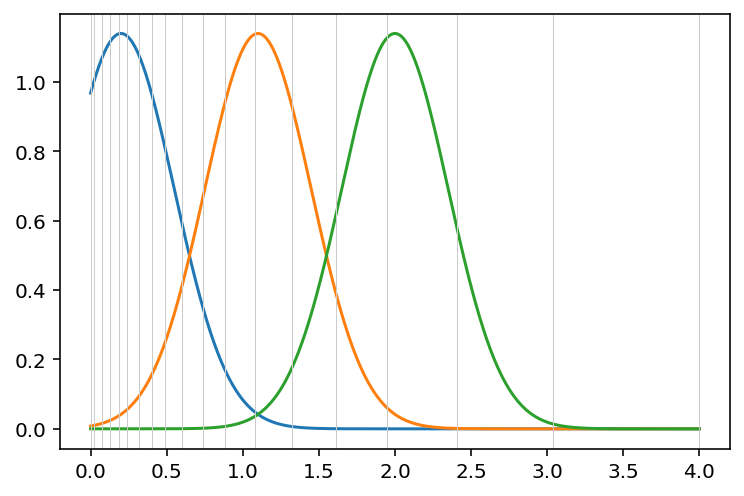

In [23]:
# Define n(z)'s
zz = np.linspace(0,4,1000)
zmids = np.linspace(0.2,2.,3)
nz_func = lambda z : lambda x : scipy.stats.norm.pdf(x, loc=z, scale=0.35)
nzs = [nz_func(_z) for _z in zmids]

# Plot n(z)'s and shell redshifts
for nz in nzs:
    plt.plot(zz, nz(zz))
for z in reader.zsnapshots:
    plt.axvline(x=z, c='.8', lw=.5)

In [24]:
kappa_dir = '/global/cscratch1/sd/xuod/HACC/kappa_test_shells_z19_subsampleauto/'
lensing = pollux.BornLensingBuilder(builder, nzs, save_dir=kappa_dir)

In [26]:
kappas, weights = lensing.construct_kappas()

/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:920: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("viridis").copy()
  newcm.set_over(newcm(1.0))
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:921: MatplotlibDeprecationWarning: You are modifying the state of a globally registered colormap. This has been deprecated since 3.3 and in 3.6, you will not be able to modify a registered colormap in-place. To remove this warning, you can make a copy of the colormap first. cmap = mpl.cm.get_cmap("viridis").copy()
  newcm.set_under(bgcolor)
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:922: MatplotlibDeprecationWarning: You are modifyin

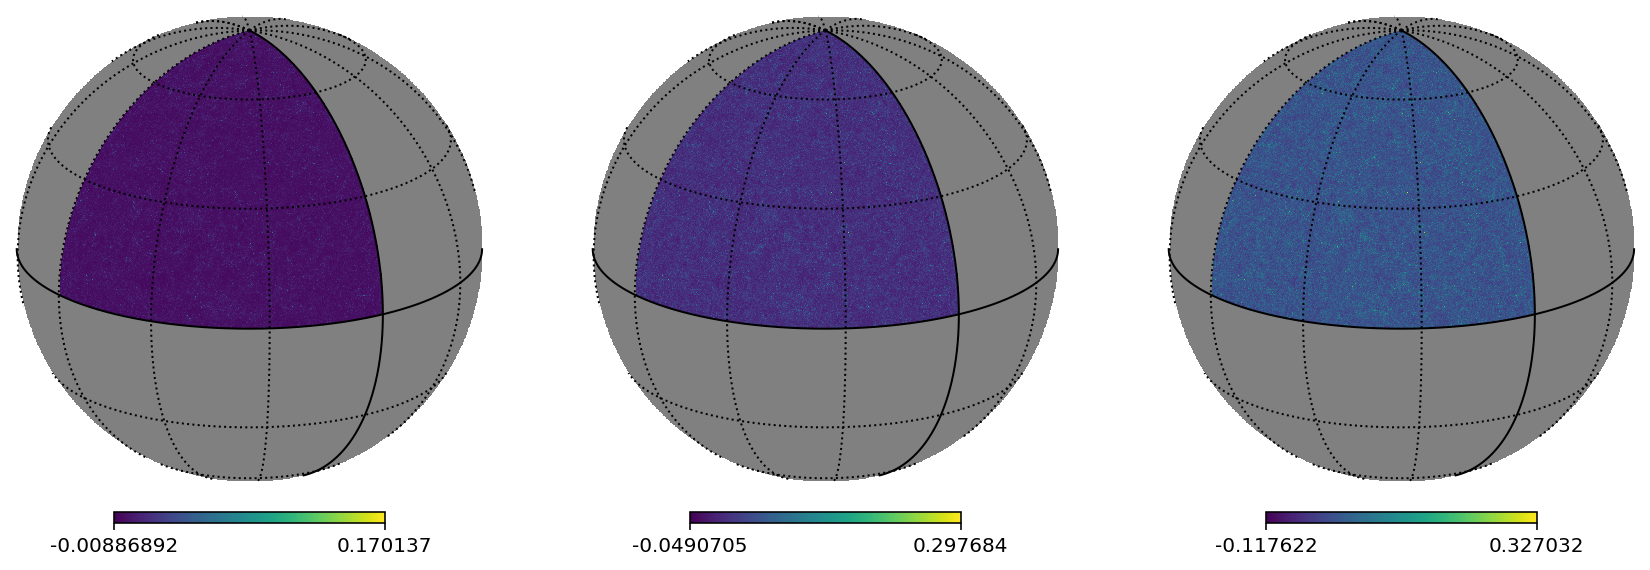

In [27]:
lensing.plot_kappas(kappas, cbar=True)

In [28]:
gammas = lensing.get_shear_maps(kappas)

/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/sphtfunc.py:822: UserWarning: Sigma is 0.000000 arcmin (0.000000 rad) 
  warnings.warn(
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/sphtfunc.py:827: UserWarning: -> fwhm is 0.000000 arcmin
  warnings.warn(


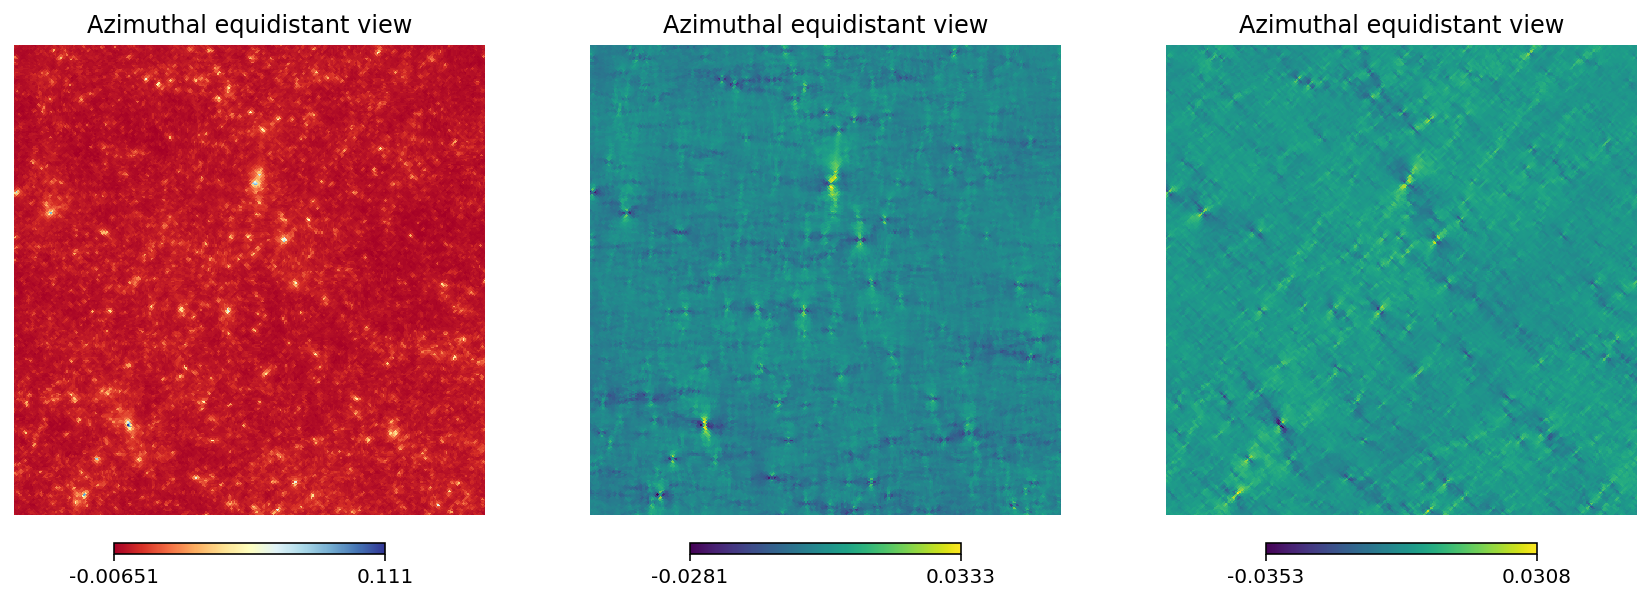

In [29]:
plt.figure(figsize=(12,4))
hp.azeqview(kappas[0].generate_healpix_map(), rot=(35,20), cmap=mpl.cm.RdYlBu, reso=0.5, sub=131)
hp.azeqview(gammas[0][0].generate_healpix_map(), rot=(35,20), cmap=mpl.cm.viridis, reso=0.5, sub=132)
hp.azeqview(gammas[0][1].generate_healpix_map(), rot=(35,20), cmap=mpl.cm.viridis, reso=0.5, sub=133)

/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:541: UserWarning: 0.0 180.0 -180.0 180.0
  warnings.warn(
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:656: UserWarning: The interval between parallels is 30 deg -0.00'.
  warnings.warn(
/global/homes/x/xuod/.conda/envs/myenv3/lib/python3.8/site-packages/healpy/projaxes.py:664: UserWarning: The interval between meridians is 30 deg -0.00'.
  warnings.warn(


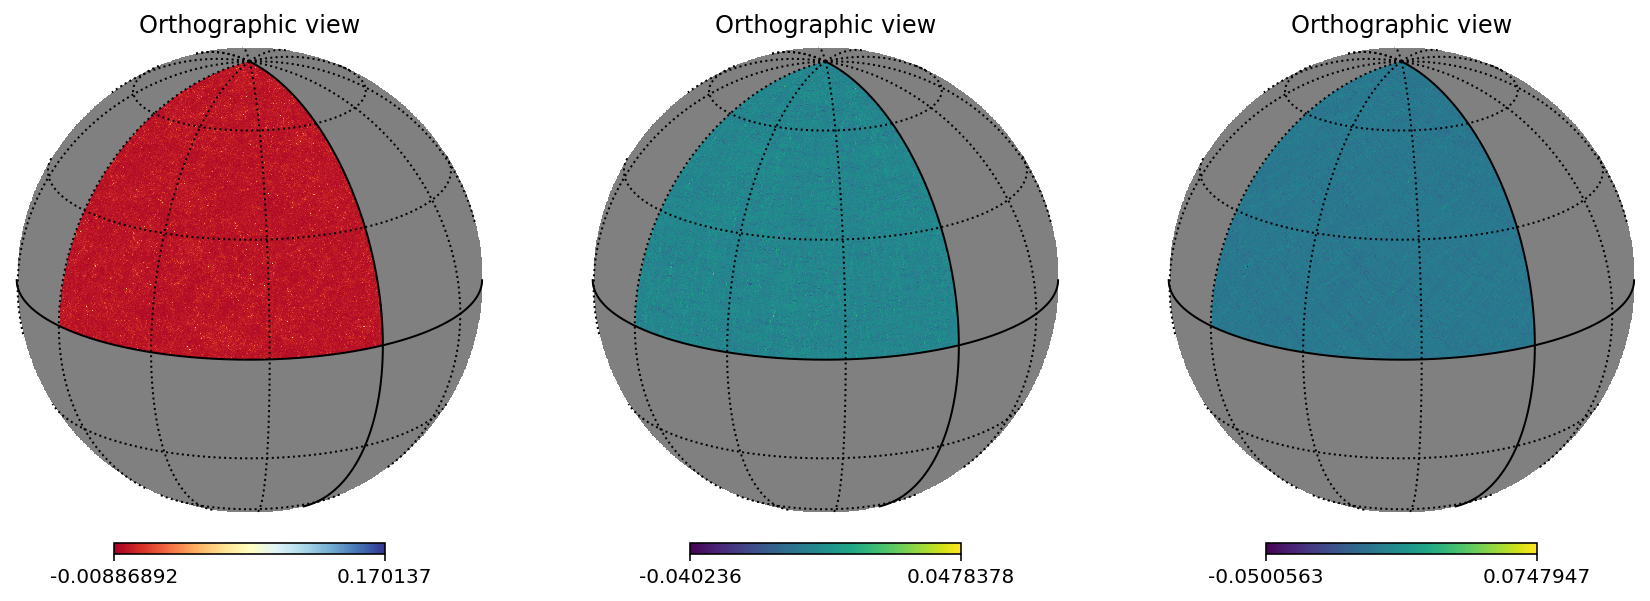

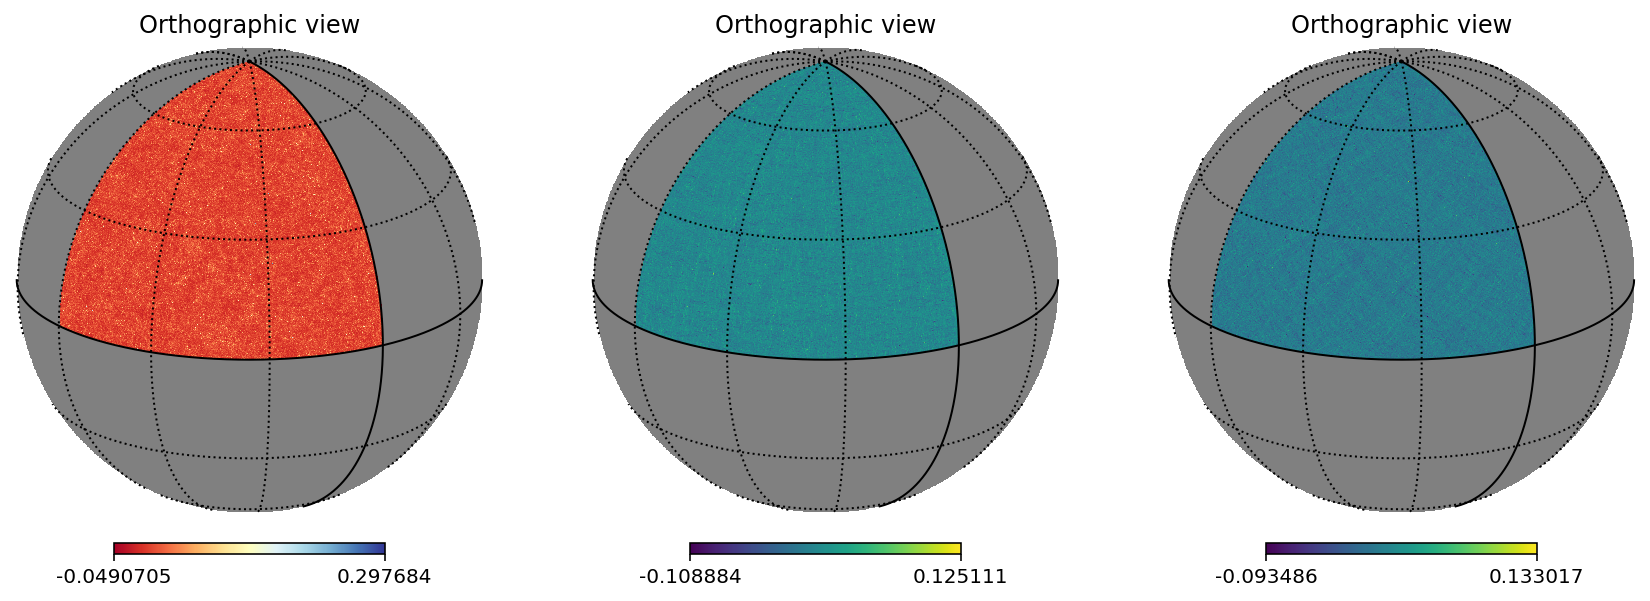

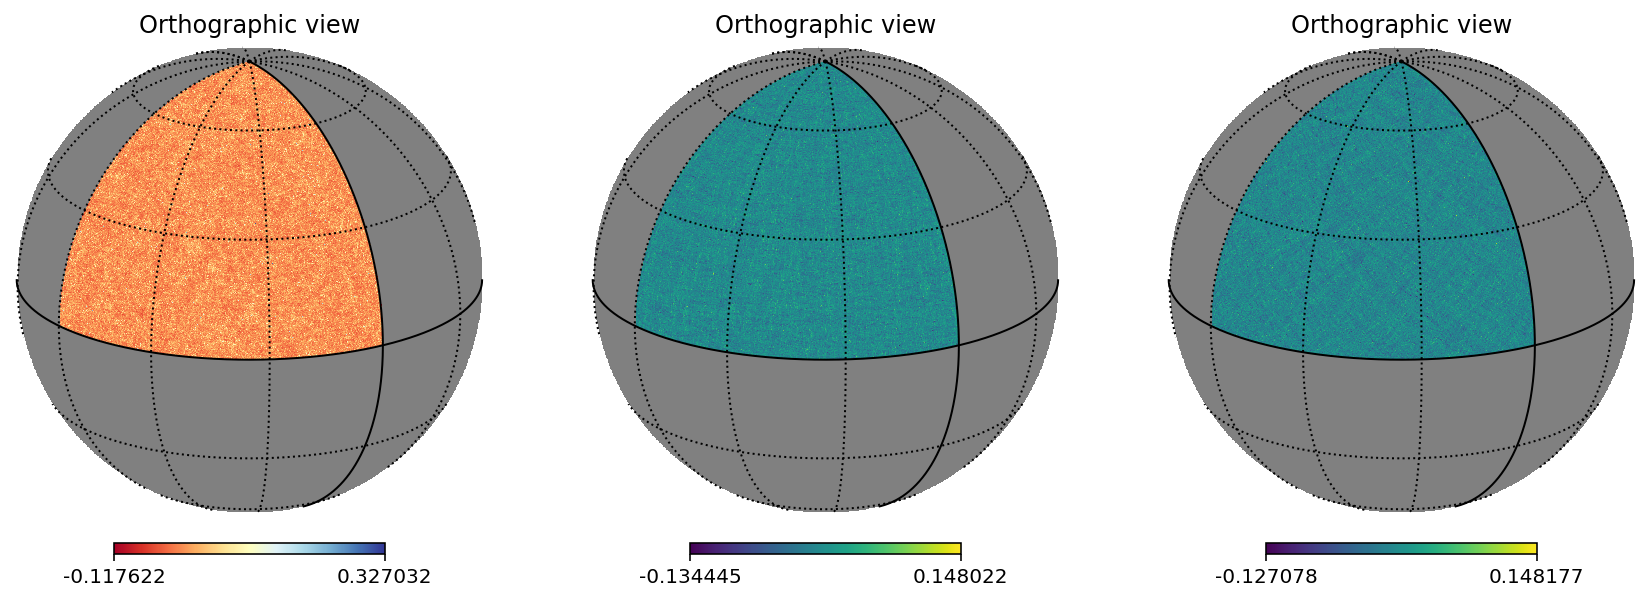

In [30]:
for i in range(3):
    plt.figure(figsize=(12,4))
    hp.orthview(kappas[i].generate_healpix_map(), rot=(35,20), half_sky=True, cmap=mpl.cm.RdYlBu, sub=131)
    hp.orthview(gammas[i][0].generate_healpix_map(), rot=(35,20), half_sky=True, cmap=mpl.cm.viridis, sub=132)
    hp.orthview(gammas[i][1].generate_healpix_map(), rot=(35,20), half_sky=True, cmap=mpl.cm.viridis, sub=133)
    hp.graticule()

In [31]:
ell, cls_kappa_obs = lensing.compute_kappas_cls()

Loading workspace in /global/cscratch1/sd/xuod/HACC/shells_z19_subsampleauto/wsp_hacc_nside2048.wsp


In [32]:
ell, cls_kappa_pred = lensing.predict_kappas_cls()

Loading workspace in /global/cscratch1/sd/xuod/HACC/shells_z19_subsampleauto/wsp_hacc_nside2048.wsp


In [34]:
wsp, mask, b = builder.get_cls_wsp()

Loading workspace in /global/cscratch1/sd/xuod/HACC/shells_z19_subsampleauto/wsp_hacc_nside2048.wsp


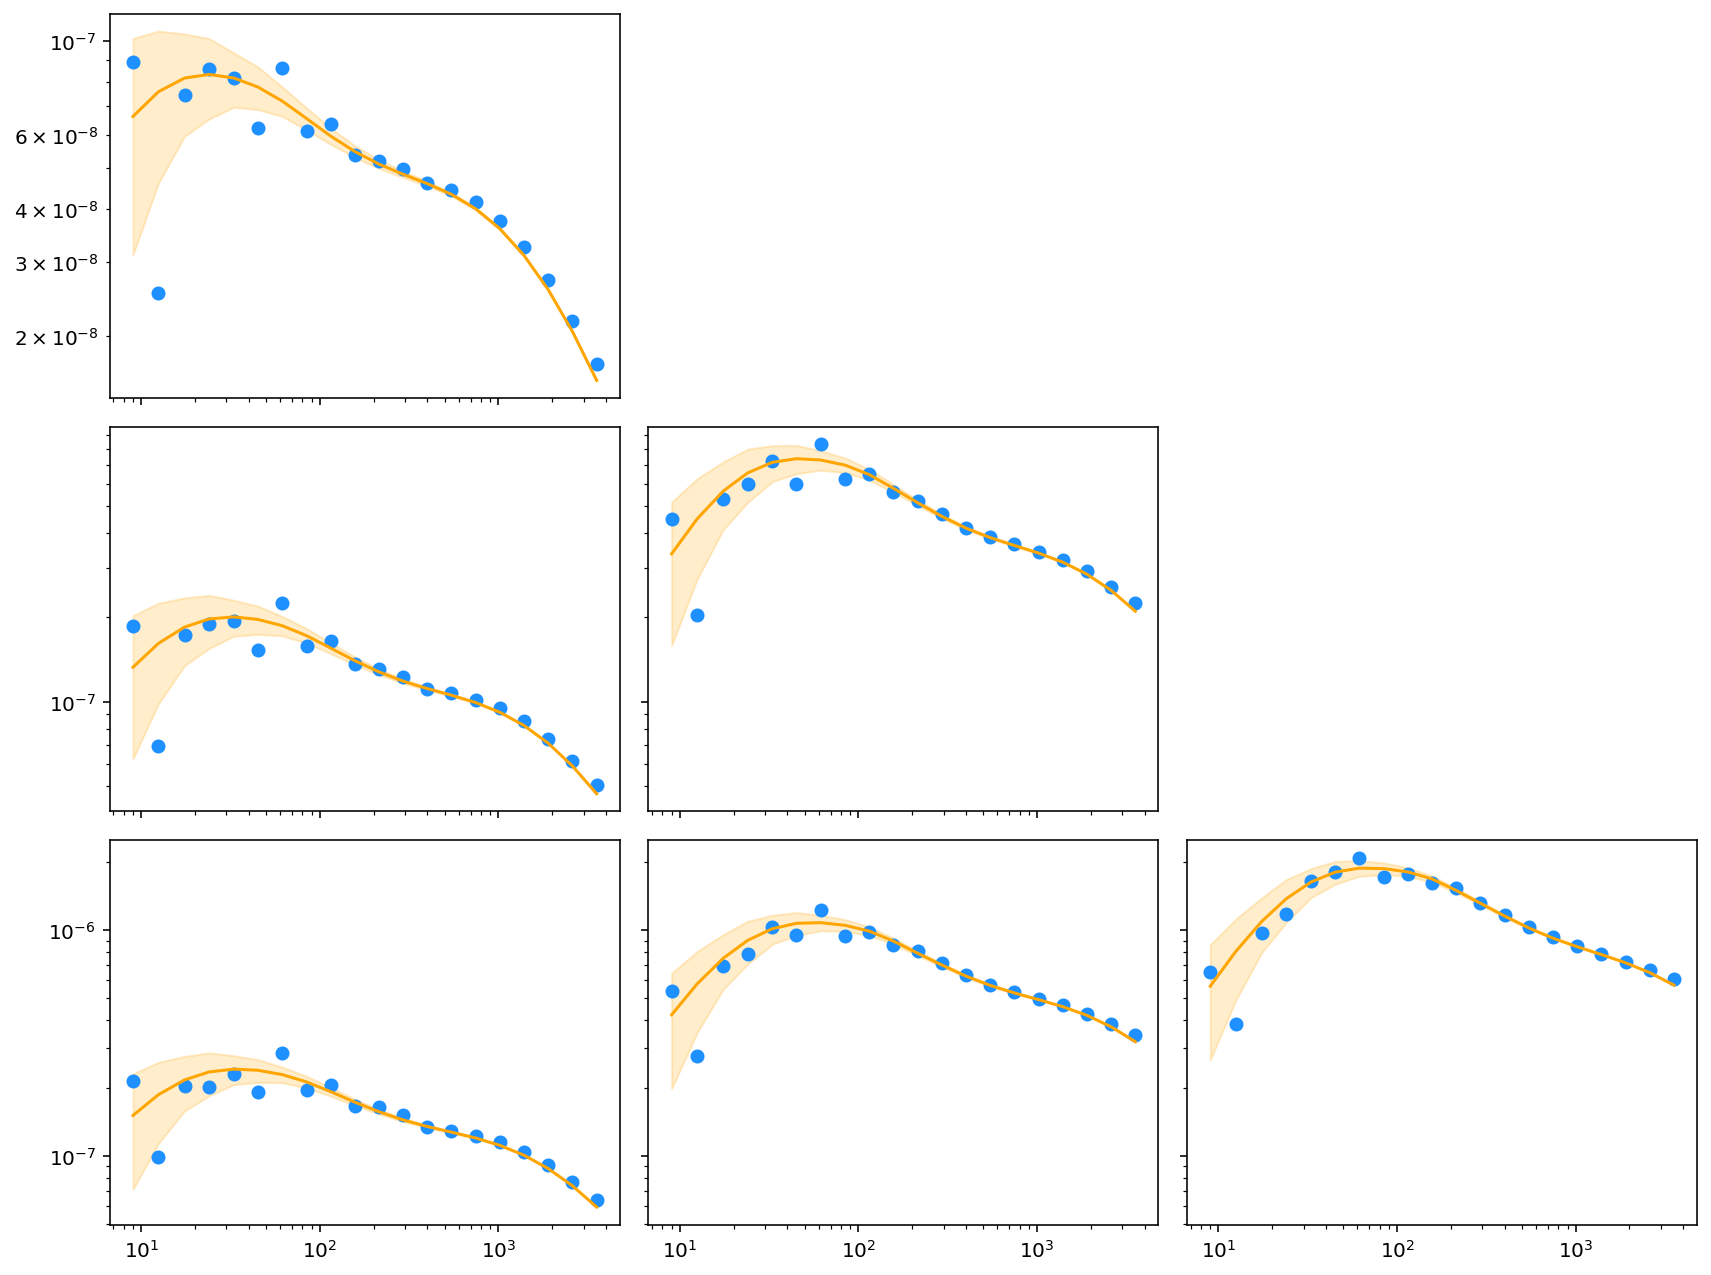

In [35]:
n = lensing.nkappas
fig, axes = plt.subplots(n, n, figsize=(4*n,3*n), sharex=True, sharey='row')
for i in range(n):
    for j in range(n):
        ax = axes[i,j]
        if j>i:
            ax.axis('off')
        else:
            ax.loglog(ell, ell*cls_kappa_obs[i,j], marker='o', c='dodgerblue', ls=' ')[0]
            ax.semilogx(ell, ell*cls_kappa_pred[i,j], ls='-', label=f'{i+1}-{j+1}', c='orange')

            # approximate error bars (noiseless)
            dcl = np.sqrt(2* (cls_kappa_pred[i,j])**2 / ((2*ell+1.)*(1/8.)*b.get_nell_list()))
            ax.fill_between(ell, ell*(cls_kappa_pred[i,j]-dcl), ell*(cls_kappa_pred[i,j]+dcl), color='orange', alpha=0.2, zorder=-99)

plt.tight_layout()